In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [3]:
df = pd.read_csv(r"D:\BDA_0024\APS_LAB\datasets\food-texture.csv")

In [4]:
df.head()

,Unnamed: 0,Oil,Density,Crispy,Fracture,Hardness
0,B110,16.5,2955,10,23,97
1,B136,17.7,2660,14,9,139
2,B171,16.2,2870,12,17,143
3,B192,16.7,2920,10,31,95
4,B225,16.3,2975,11,26,143


In [5]:
# Number of rows and columns
print("Shape of dataset:", df.shape)

Shape of dataset: (50, 6)


In [8]:
# Display all column names
print(df.columns)

Index(['Unnamed: 0', 'Oil', 'Density', 'Crispy', 'Fracture', 'Hardness'], dtype='str')


In [10]:
df.dtypes

Unnamed: 0        str
Oil           float64
Density         int64
Crispy          int64
Fracture        int64
Hardness        int64
dtype: object

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50 non-null     str    
 1   Oil         50 non-null     float64
 2   Density     50 non-null     int64  
 3   Crispy      50 non-null     int64  
 4   Fracture    50 non-null     int64  
 5   Hardness    50 non-null     int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 2.5 KB


In [12]:
df.describe()

,Oil,Density,Crispy,Fracture,Hardness
count,50.000000,50.00000,50.000000,50.000000,50.000000
mean,17.202000,2857.60000,11.520000,20.860000,128.180000
std,1.592007,124.49998,1.775571,5.466073,31.127578
min,13.700000,2570.00000,7.000000,9.000000,63.000000
25%,16.300000,2772.50000,10.000000,17.000000,107.250000
50%,16.900000,2867.50000,12.000000,21.000000,126.000000
75%,18.100000,2945.00000,13.000000,25.000000,143.750000
max,21.200000,3125.00000,15.000000,33.000000,192.000000


In [13]:
print(df.isnull().sum())

Unnamed: 0    0
Oil           0
Density       0
Crispy        0
Fracture      0
Hardness      0
dtype: int64


In [14]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [15]:
df = df.drop(columns=["Unnamed: 0"])

In [16]:
print(df.columns)

Index(['Oil', 'Density', 'Crispy', 'Fracture', 'Hardness'], dtype='str')


In [17]:
df.head()

,Oil,Density,Crispy,Fracture,Hardness
0,16.5,2955,10,23,97
1,17.7,2660,14,9,139
2,16.2,2870,12,17,143
3,16.7,2920,10,31,95
4,16.3,2975,11,26,143


****Descriptive STatistics***

In [36]:
# Calculate a full descriptive-statistics table for each numerical column
statistics_table = pd.DataFrame({
    "Count": df.count(),
    "Mean": df.mean(),
    "Median": df.median(),
    "Mode": df.mode().iloc[0],
    "Standard Deviation": df.std(),
    "Variance": df.var(),
    "Minimum": df.min(),
    "Q1 (25%)": df.quantile(0.25),
    "Q2 (50%)": df.quantile(0.50),
    "Q3 (75%)": df.quantile(0.75),
    "Maximum": df.max(),
    "Range": df.max() - df.min(),
    "IQR": df.quantile(0.75) - df.quantile(0.25),
    "Skewness": df.skew(),
    "Kurtosis": df.kurtosis()
})

display(statistics_table.round(3))

,Count,Mean,Median,Mode,Standard Deviation,Variance,Minimum,Q1 (25%),Q2 (50%),Q3 (75%),Maximum,Range,IQR,Skewness,Kurtosis
Oil,50,17.202,16.9,16.3,1.592,2.534,13.7,16.30,16.9,18.10,21.2,7.5,1.8,0.441,0.610
Density,50,2857.600,2867.5,2920.0,124.500,15500.245,2570.0,2772.50,2867.5,2945.00,3125.0,555.0,172.5,-0.191,-0.265
Crispy,50,11.520,12.0,10.0,1.776,3.153,7.0,10.00,12.0,13.00,15.0,8.0,3.0,-0.296,-0.287
Fracture,50,20.860,21.0,20.0,5.466,29.878,9.0,17.00,21.0,25.00,33.0,24.0,8.0,-0.115,-0.438
Hardness,50,128.180,126.0,123.0,31.128,968.926,63.0,107.25,126.0,143.75,192.0,129.0,36.5,0.007,-0.218


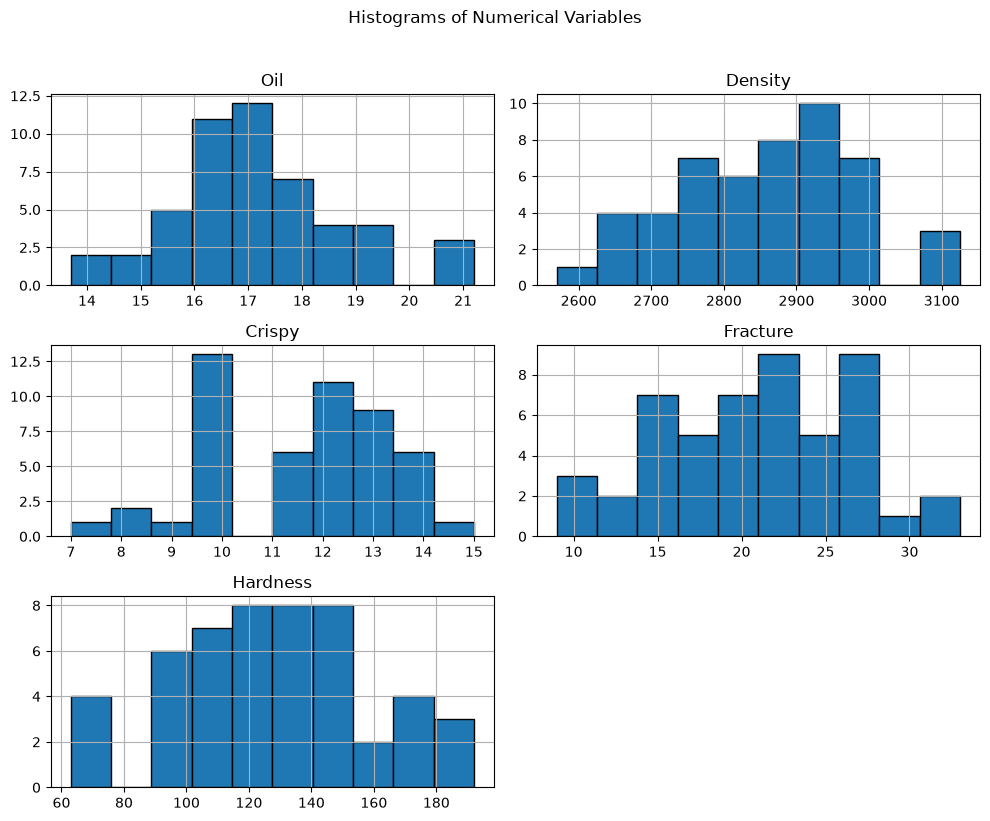

In [37]:
# Histograms show how values are distributed
df.hist(figsize=(10, 8), bins=10, edgecolor="black")
plt.suptitle("Histograms of Numerical Variables", y=1.02)
plt.tight_layout()
plt.show()

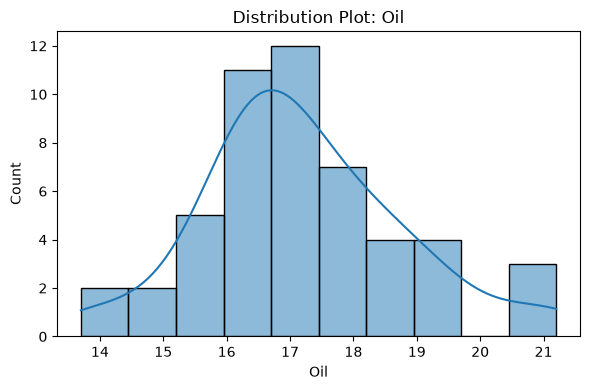

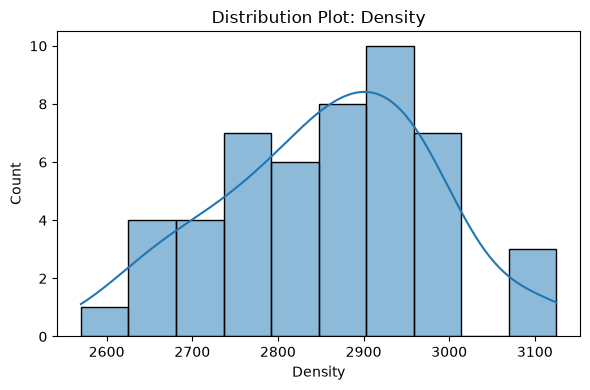

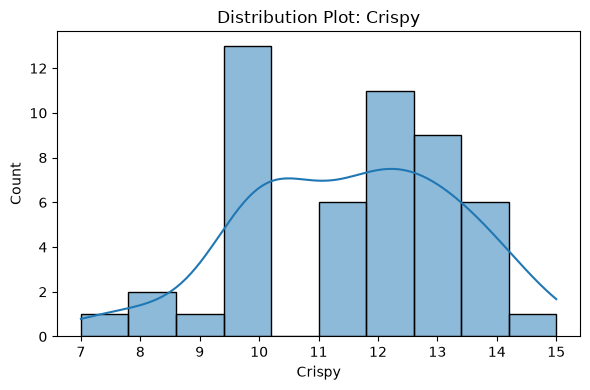

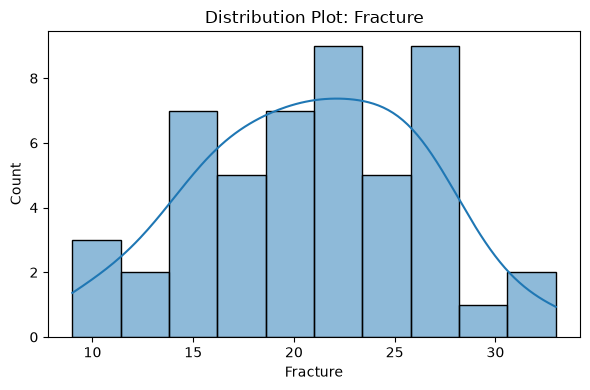

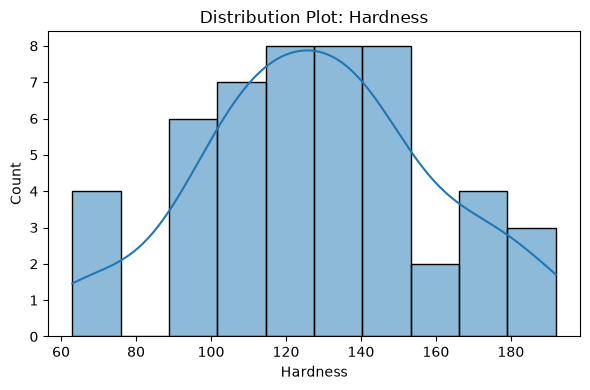

In [38]:
# Distribution plots show histogram bars and a smoothed density curve
for column in df.columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(data=df, x=column, kde=True, bins=10)
    plt.title(f"Distribution Plot: {column}")
    plt.tight_layout()
    plt.show()

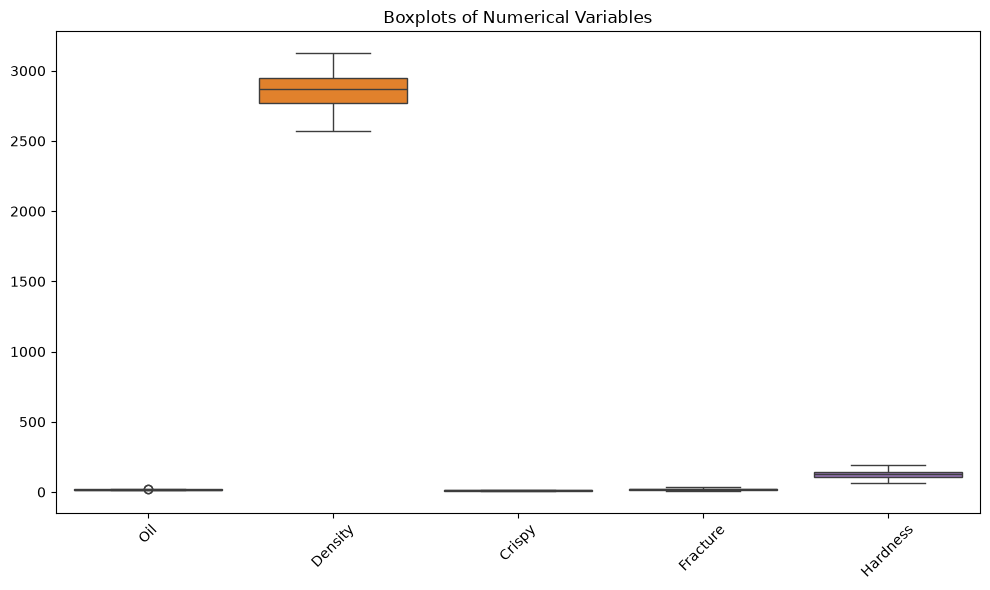

In [39]:
# Boxplots visually flag possible outliers
plt.figure(figsize=(10, 6))
sns.boxplot(data=df)
plt.title("Boxplots of Numerical Variables")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

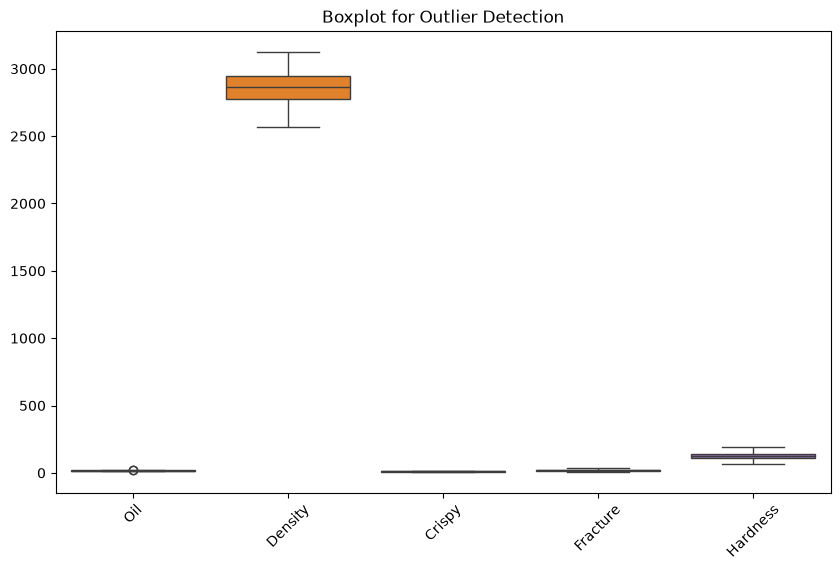

In [35]:
# Plot boxplots to visually identify potential outliers
plt.figure(figsize=(10, 6))

sns.boxplot(data=df)

plt.title("Boxplot for Outlier Detection")
plt.xticks(rotation=45)
plt.show()

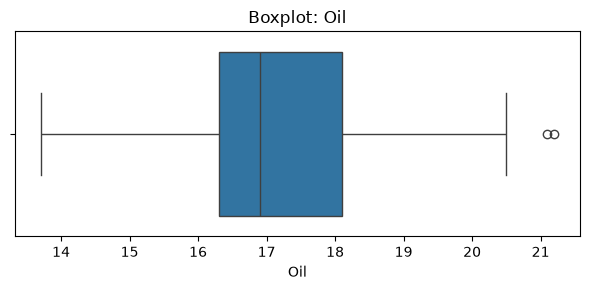

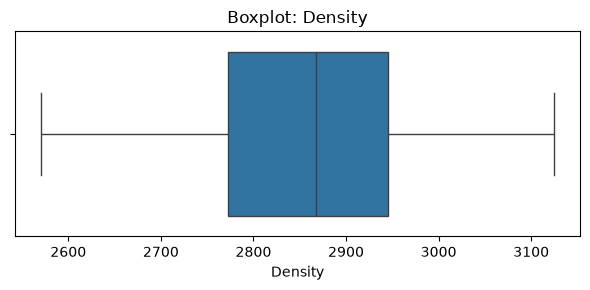

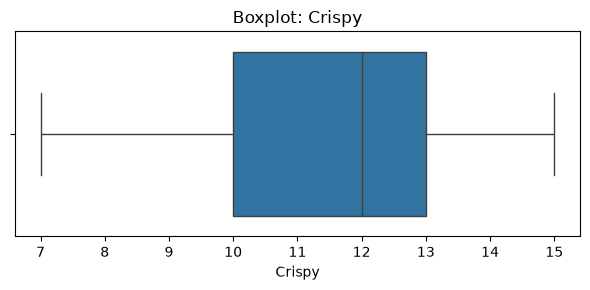

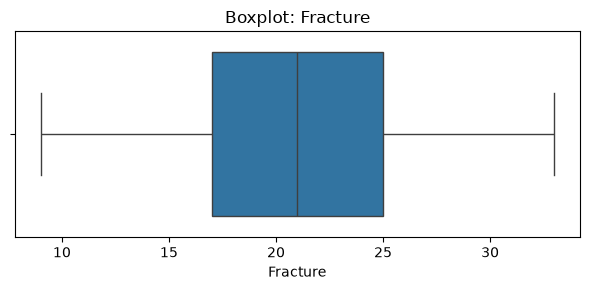

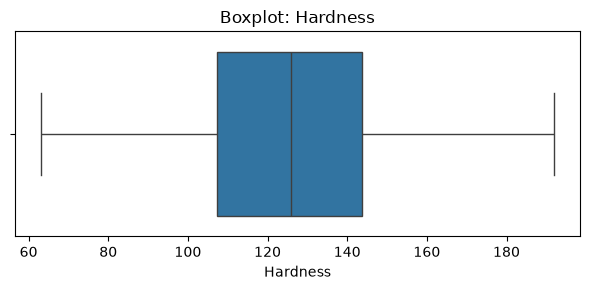

In [40]:
# Individual boxplots are easier to read when columns have different scales
for column in df.columns:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot: {column}")
    plt.tight_layout()
    plt.show()

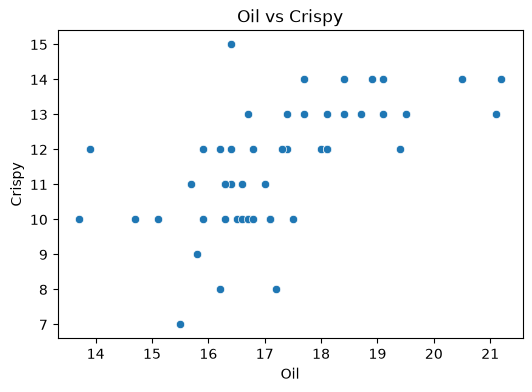

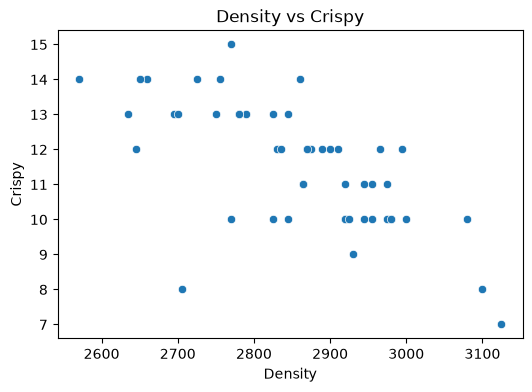

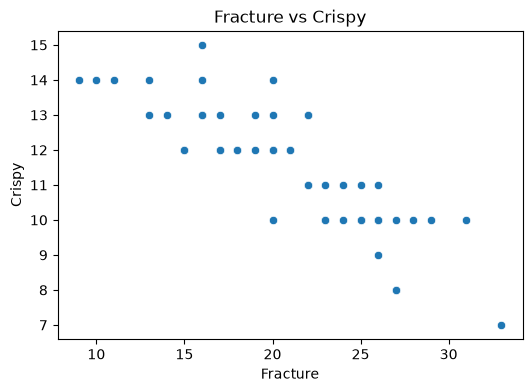

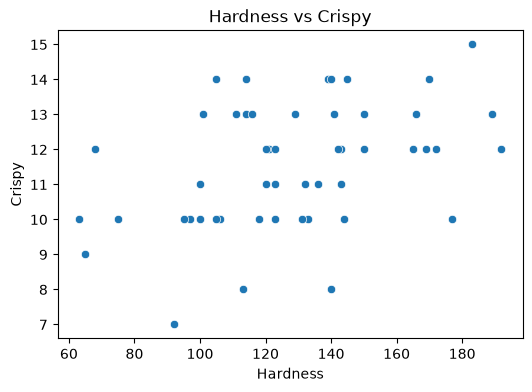

In [22]:
# Create one scatter plot for each feature against Crispy
for feature in features:
    plt.figure(figsize=(6, 4))

    sns.scatterplot(data=df, x=feature, y="Crispy")

    plt.title(feature + " vs Crispy")
    plt.show()

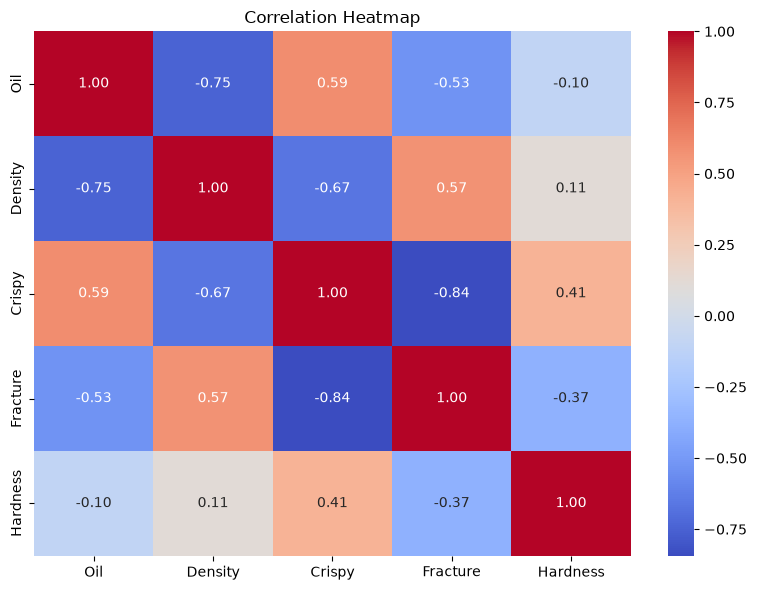

In [42]:
# Correlation heatmap
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

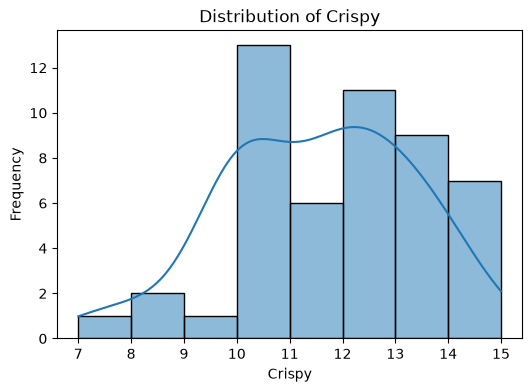

In [23]:
# Examine the distribution of the target variable
plt.figure(figsize=(6, 4))

sns.histplot(df["Crispy"], bins=8, kde=True)

plt.title("Distribution of Crispy")
plt.xlabel("Crispy")
plt.ylabel("Frequency")
plt.show()

***defining input and output variable***

In [44]:
# X = input features; y = target value to predict
X = df[["Oil", "Density", "Fracture", "Hardness"]]
y = df["Crispy"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (50, 4)
Target shape: (50,)


In [45]:
# Keep 80% of data for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (40, 4)
Testing features: (10, 4)


In [48]:
from sklearn.preprocessing import MinMaxScaler
# Normalize the features. Fit the scaler on training data only to avoid data leakage.
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [49]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [50]:
# Display model intercept and coefficients (coefficients are for scaled features)
print("Intercept:", round(model.intercept_, 4))

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

Intercept: 13.0492
Oil: 1.3746
Density: -2.2915
Fracture: -3.5623
Hardness: 1.9981


In [51]:
# Display the fitted equation. X values in this equation are normalized.
b0 = model.intercept_
b1, b2, b3, b4 = model.coef_

print(
    f"Crispy = {b0:.4f} "
    f"+ ({b1:.4f} * Oil_scaled) "
    f"+ ({b2:.4f} * Density_scaled) "
    f"+ ({b3:.4f} * Fracture_scaled) "
    f"+ ({b4:.4f} * Hardness_scaled)"
)

Crispy = 13.0492 + (1.3746 * Oil_scaled) + (-2.2915 * Density_scaled) + (-3.5623 * Fracture_scaled) + (1.9981 * Hardness_scaled)


In [52]:
# Predict Crispy for the unseen test data
y_pred = model.predict(X_test_scaled)

results = pd.DataFrame({
    "Actual Crispy": y_test.to_numpy(),
    "Predicted Crispy": y_pred
})
results["Error"] = results["Actual Crispy"] - results["Predicted Crispy"]

display(results.round(3))

,Actual Crispy,Predicted Crispy,Error
0,12,11.401,0.599
1,10,9.746,0.254
2,10,9.647,0.353
3,11,10.597,0.403
4,12,12.254,-0.254
5,13,13.531,-0.531
6,10,9.942,0.058
7,12,12.913,-0.913
8,7,7.543,-0.543
9,14,14.270,-0.270


In [54]:
# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R-squared:", round(r2, 3))

MAE: 0.418
MSE: 0.226
RMSE: 0.476
R-squared: 0.935


In [55]:
# Compare performance on training and testing data
y_train_pred = model.predict(X_train_scaled)

print("Training R-squared:", round(r2_score(y_train, y_train_pred), 3))
print("Testing R-squared:", round(r2_score(y_test, y_pred), 3))

Training R-squared: 0.776
Testing R-squared: 0.935


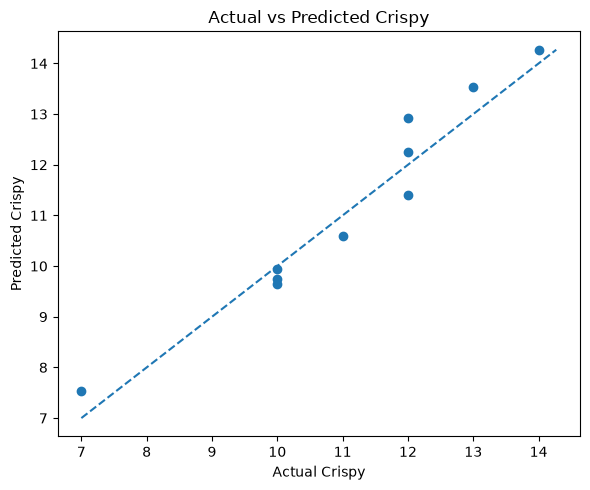

In [56]:
# Points closer to the diagonal indicate more accurate predictions
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")

plt.xlabel("Actual Crispy")
plt.ylabel("Predicted Crispy")
plt.title("Actual vs Predicted Crispy")
plt.tight_layout()
plt.show()

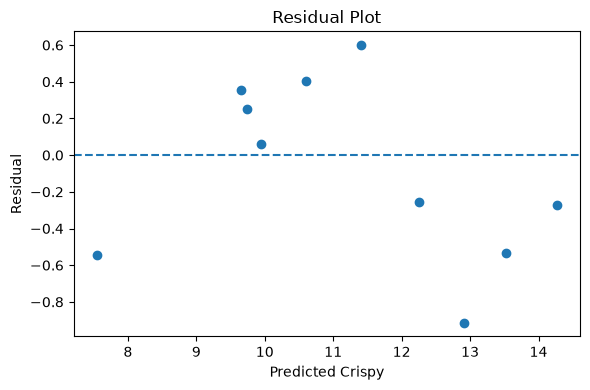

In [57]:
# Residual = actual value - predicted value
residuals = y_test - y_pred

plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Crispy")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

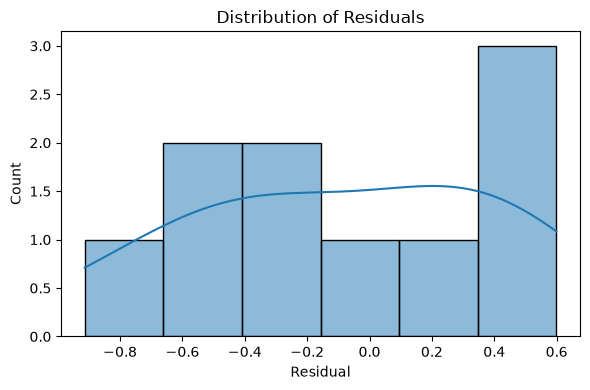

Mean residual: -0.084


In [58]:
# Distribution of model errors
plt.figure(figsize=(6, 4))
sns.histplot(residuals, bins=6, kde=True)
plt.xlabel("Residual")
plt.title("Distribution of Residuals")
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 3))